## Step 1

In [25]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

## Step 2:Load the dataset and display 5 record

In [26]:

df = pd.read_csv("rwandalandslidedataset/train.csv")
df.head()

,id,annual_income,debt_to_income_ratio,credit_score,loan_amount,interest_rate,gender,marital_status,education_level,employment_status,loan_purpose,grade_subgrade,loan_paid_back
0,0,29367.99,0.084,736,2528.42,13.67,Female,Single,High School,Self-employed,Other,C3,1.0
1,1,22108.02,0.166,636,4593.10,12.92,Male,Married,Master's,Employed,Debt consolidation,D3,0.0
2,2,49566.20,0.097,694,17005.15,9.76,Male,Single,High School,Employed,Debt consolidation,C5,1.0
3,3,46858.25,0.065,533,4682.48,16.10,Female,Single,High School,Employed,Debt consolidation,F1,1.0
4,4,25496.70,0.053,665,12184.43,10.21,Male,Married,High School,Employed,Other,D1,1.0


## Step 3

In [27]:
# (a) Shape
print("Shape (rows, columns):", df.shape)

# (b) Unique values of the target
print("\nUnique values of loan_paid_back:", df["loan_paid_back"].unique())

# (c) Missing values per column
print("\nMissing values per column:")
print(df.isnull().sum())

original_rows = df.shape[0]   # saved for the check in Step 12

Shape (rows, columns): (593994, 13)

Unique values of loan_paid_back: [1. 0.]

Missing values per column:
id                      0
annual_income           0
debt_to_income_ratio    0
credit_score            0
loan_amount             0
interest_rate           0
gender                  0
marital_status          0
education_level         0
employment_status       0
loan_purpose            0
grade_subgrade          0
loan_paid_back          0
dtype: int64


## Step 4

loan_paid_back
1.0    474494
0.0    119500
Name: count, dtype: int64

Percentages:
loan_paid_back
1.0    79.881952
0.0    20.118048
Name: proportion, dtype: float64


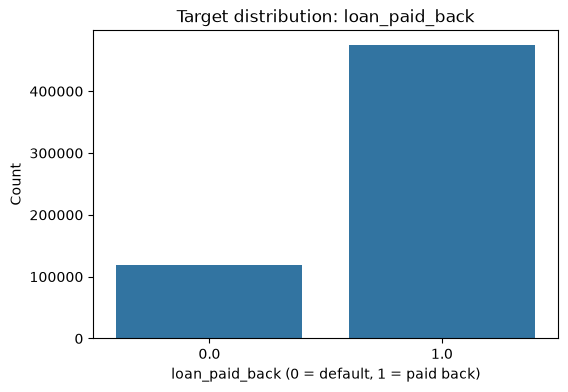

In [28]:
print(df["loan_paid_back"].value_counts())
print("\nPercentages:")
print(df["loan_paid_back"].value_counts(normalize=True) * 100)

plt.figure(figsize=(6, 4))
sns.countplot(x="loan_paid_back", data=df)
plt.title("Target distribution: loan_paid_back")
plt.xlabel("loan_paid_back (0 = default, 1 = paid back)")
plt.ylabel("Count")
plt.show()

## Step 5

In [7]:
# Numeric columns only (id is just an identifier and loan_paid_back is the target, so both are excluded)
numeric_cols = [c for c in df.select_dtypes(include=[np.number]).columns
                if c not in ["id", "loan_paid_back"]]

# IQR bounds
Q1 = df[numeric_cols].quantile(0.25)
Q3 = df[numeric_cols].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# True where a value is an outlier
outlier_mask = (df[numeric_cols] < lower_bound) | (df[numeric_cols] > upper_bound)

# (a) Total number of outlier values
print("(a) Total number of outlier values:", int(outlier_mask.sum().sum()))

# (b) Outliers per numeric column
print("\n(b) Outliers per numeric column:")
print(outlier_mask.sum())

# (c) Rows with at least one outlier
rows_with_outlier = outlier_mask.any(axis=1)
print("\n(c) Number of rows with at least one outlier:", int(rows_with_outlier.sum()))
display(df[rows_with_outlier].head())

# (d) DataFrame containing all outlier rows
outlier_df = df[rows_with_outlier]
print("\n(d) Outlier rows dataframe shape:", outlier_df.shape)
outlier_df

(a) Total number of outlier values: 47412

(b) Outliers per numeric column:
annual_income           15917
debt_to_income_ratio    17556
credit_score             5901
loan_amount              2902
interest_rate            5136
dtype: int64

(c) Number of rows with at least one outlier: 45437


,id,annual_income,debt_to_income_ratio,credit_score,loan_amount,interest_rate,gender,marital_status,education_level,employment_status,loan_purpose,grade_subgrade,loan_paid_back
3,3,46858.25,0.065,533,4682.48,16.10,Female,Single,High School,Employed,Debt consolidation,F1,1.0
22,22,135416.72,0.160,661,12404.14,13.30,Male,Single,High School,Unemployed,Debt consolidation,D1,0.0
26,26,24001.73,0.284,669,13863.79,10.88,Female,Married,Master's,Employed,Debt consolidation,D4,0.0
30,30,15557.19,0.152,591,15257.87,17.76,Male,Married,High School,Employed,Education,E5,1.0
36,36,48602.37,0.091,531,13379.10,15.67,Male,Married,Bachelor's,Unemployed,Debt consolidation,F4,0.0



(d) Outlier rows dataframe shape: (45437, 13)


,id,annual_income,debt_to_income_ratio,credit_score,loan_amount,interest_rate,gender,marital_status,education_level,employment_status,loan_purpose,grade_subgrade,loan_paid_back
3,3,46858.25,0.065,533,4682.48,16.10,Female,Single,High School,Employed,Debt consolidation,F1,1.0
22,22,135416.72,0.160,661,12404.14,13.30,Male,Single,High School,Unemployed,Debt consolidation,D1,0.0
26,26,24001.73,0.284,669,13863.79,10.88,Female,Married,Master's,Employed,Debt consolidation,D4,0.0
30,30,15557.19,0.152,591,15257.87,17.76,Male,Married,High School,Employed,Education,E5,1.0
36,36,48602.37,0.091,531,13379.10,15.67,Male,Married,Bachelor's,Unemployed,Debt consolidation,F4,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
593919,593919,52233.83,0.284,699,16686.17,15.67,Female,Single,PhD,Employed,Debt consolidation,C1,1.0
593934,593934,51139.38,0.357,717,22458.69,11.54,Male,Single,High School,Employed,Other,C5,1.0
593948,593948,160982.65,0.102,723,8090.90,7.21,Female,Married,Bachelor's,Employed,Debt consolidation,C3,1.0
593965,593965,14798.35,0.061,522,27995.88,17.62,Male,Married,High School,Employed,Debt consolidation,F4,1.0


## Step 6

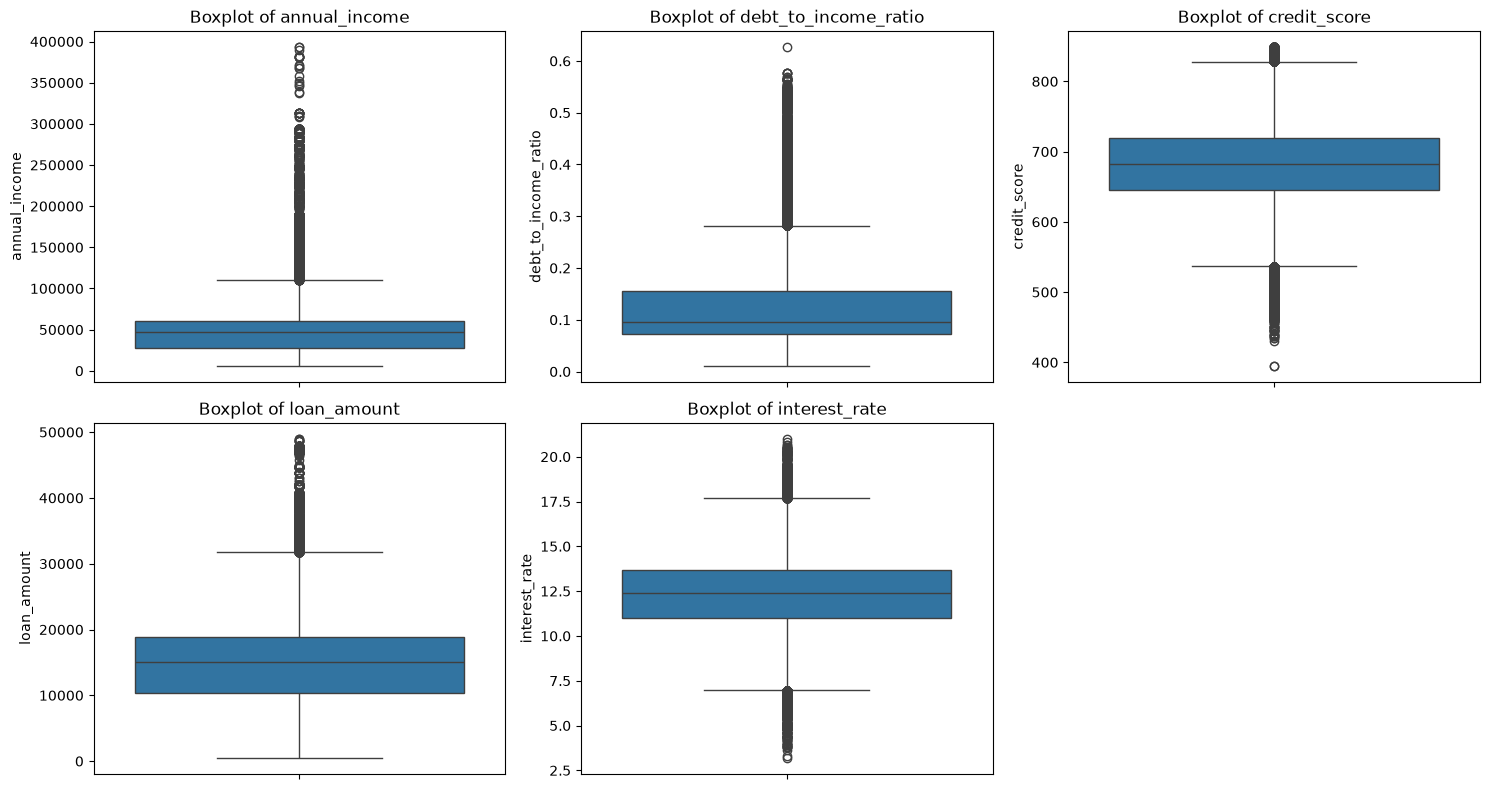

In [8]:
n = len(numeric_cols)
cols = 3
rows = int(np.ceil(n / cols))
fig, axes = plt.subplots(rows, cols, figsize=(5 * cols, 4 * rows))
axes = np.array(axes).flatten()

for i, col in enumerate(numeric_cols):
    sns.boxplot(y=df[col], ax=axes[i])
    axes[i].set_title(f"Boxplot of {col}")

for j in range(n, len(axes)):
    axes[j].axis("off")

plt.tight_layout()
plt.show()

## Step 7

In [9]:
# (a) Remove all outlier rows using the IQR bounds
df_clean = df[~rows_with_outlier].reset_index(drop=True)

# (b) New shape
print("Shape before outlier removal:", df.shape)
print("Shape after outlier removal :", df_clean.shape)

cleaned_rows = df_clean.shape[0]   # saved for the check in Step 12

Shape before outlier removal: (593994, 13)
Shape after outlier removal : (548557, 13)


## Step 8

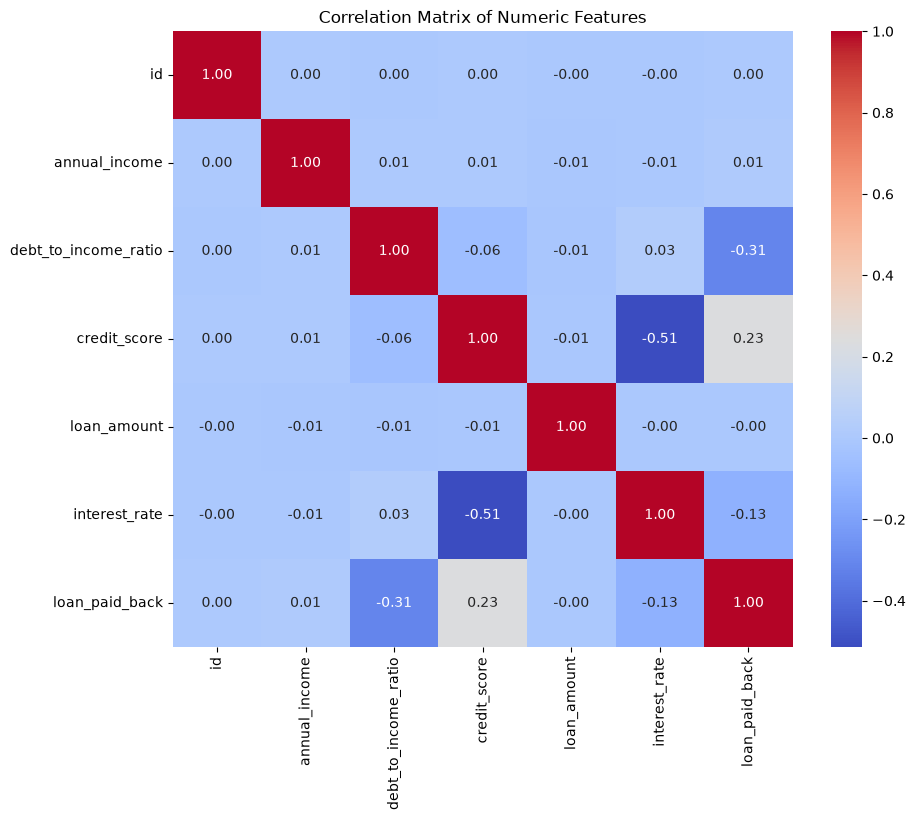

In [10]:
corr_matrix = df_clean.select_dtypes(include=[np.number]).corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Matrix of Numeric Features")
plt.show()

## Step 9

In [11]:
df_clean = df_clean.drop(columns=["id"])
print("'id' still in dataframe?", "id" in df_clean.columns)
print("Columns:", list(df_clean.columns))

'id' still in dataframe? False
Columns: ['annual_income', 'debt_to_income_ratio', 'credit_score', 'loan_amount', 'interest_rate', 'gender', 'marital_status', 'education_level', 'employment_status', 'loan_purpose', 'grade_subgrade', 'loan_paid_back']


## Step 10

In [12]:
# (a) Categorical features
categorical_cols = df_clean.select_dtypes(include=["object", "category"]).columns.tolist()
print("(a) Categorical features:", categorical_cols)

# (b) + (c) Label encode each categorical column and update the SAME columns
label_encoders = {}
for col in categorical_cols:
    le = LabelEncoder()
    df_clean[col] = le.fit_transform(df_clean[col])
    label_encoders[col] = le

# (d) First 5 records
df_clean.head()

(a) Categorical features: ['gender', 'marital_status', 'education_level', 'employment_status', 'loan_purpose', 'grade_subgrade']


,annual_income,debt_to_income_ratio,credit_score,loan_amount,interest_rate,gender,marital_status,education_level,employment_status,loan_purpose,grade_subgrade,loan_paid_back
0,29367.99,0.084,736,2528.42,13.67,0,2,1,2,6,12,1.0
1,22108.02,0.166,636,4593.10,12.92,1,1,2,0,2,17,0.0
2,49566.20,0.097,694,17005.15,9.76,1,2,1,0,2,14,1.0
3,25496.70,0.053,665,12184.43,10.21,1,1,1,0,6,15,1.0
4,44940.30,0.058,653,12159.92,12.24,1,2,0,0,6,15,1.0


## Step 11

In [13]:
X = df_clean.drop(columns=["loan_paid_back"])
y = df_clean["loan_paid_back"]
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (548557, 11)
y shape: (548557,)


## Step 12

In [15]:
# (a) Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

# (b) Notice 1 and Notice 2
total_split = len(X_train) + len(X_test)
print("\nlen(X_train) + len(X_test) =", total_split)
print("Rows after outlier removal (Step 7) =", cleaned_rows)
print("Original rows (Step 3)              =", original_rows)

print("Notice 1 (equals Step 7 rows)      :", total_split == cleaned_rows)
print("Notice 2 (differs from Step 3 rows):", total_split != original_rows)
assert total_split == cleaned_rows and total_split != original_rows, "Review your work!"

X_train: (438845, 11)
X_test : (109712, 11)
y_train: (438845,)
y_test : (109712,)

len(X_train) + len(X_test) = 548557
Rows after outlier removal (Step 7) = 548557
Original rows (Step 3)              = 593994
Notice 1 (equals Step 7 rows)      : True
Notice 2 (differs from Step 3 rows): True


## Step 13

In [16]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)   # fit on training data ONLY
X_test_scaled = scaler.transform(X_test)         # only transform test data

print("X_train_scaled:", X_train_scaled.shape)
print("X_test_scaled :", X_test_scaled.shape)

X_train_scaled: (438845, 11)
X_test_scaled : (109712, 11)


## Step 14

In [17]:
model = Sequential([
    Input(shape=(X_train_scaled.shape[1],)),
    Dense(64, activation="relu"),
    Dropout(0.2),
    Dense(32, activation="relu"),
    Dropout(0.2),
    Dense(16, activation="relu"),
    Dense(1, activation="sigmoid")      # binary classification
])

model.compile(optimizer="adam",
              loss="binary_crossentropy",
              metrics=["accuracy"])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           768 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,393 (13.25 KB)

 Trainable params: 3,393 (13.25 KB)

 Non-trainable params: 0 (0.00 B)

## Step 15

In [19]:
early_stop = EarlyStopping(monitor="val_loss",
                           patience=5,
                           restore_best_weights=True)

history = model.fit(
    X_train_scaled, y_train,
    epochs=30,
    validation_split=0.2,
    batch_size=512,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/30
686/686 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9082 - loss: 0.2511 - val_accuracy: 0.9071 - val_loss: 0.2521
Epoch 2/30
686/686 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9084 - loss: 0.2506 - val_accuracy: 0.9073 - val_loss: 0.2517
Epoch 3/30
686/686 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9084 - loss: 0.2508 - val_accuracy: 0.9069 - val_loss: 0.2528
Epoch 4/30
686/686 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9083 - loss: 0.2505 - val_accuracy: 0.9071 - val_loss: 0.2515
Epoch 5/30
686/686 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9081 - loss: 0.2504 - val_accuracy: 0.9071 - val_loss: 0.2513
Epoch 6/30
686/686 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.9083 - loss: 0.2500 - val_accuracy: 0.9067 - val_loss: 0.2517
Epoch 7/30
686/686 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9083 - loss: 0.2498 - val_accuracy: 0.9070 - val_loss: 0.2512
Epoch 8/30
686/686 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9083 - loss: 0.2500 - val_accuracy: 0.

## Step 16

In [20]:
train_loss, train_acc = model.evaluate(X_train_scaled, y_train, verbose=0)
test_loss, test_acc = model.evaluate(X_test_scaled, y_test, verbose=0)

print(f"(a) Train accuracy: {train_acc:.4f}")
print(f"(b) Test accuracy : {test_acc:.4f}")

(a) Train accuracy: 0.9085
(b) Test accuracy : 0.9081


## Step 17

In [21]:
# (a) Probabilities
y_pred_proba = model.predict(X_test_scaled)

# (b) Binary predictions with threshold 0.5
y_pred = (y_pred_proba > 0.5).astype(int)

print("First 5 probabilities:", y_pred_proba[:5].flatten())
print("First 5 predictions  :", y_pred[:5].flatten())

3429/3429 ━━━━━━━━━━━━━━━━━━━━ 4s 1ms/step
First 5 probabilities: [0.9407656  0.9653489  0.9905188  0.93595284 0.92634225]
First 5 predictions  : [1 1 1 1 1]


## Step 18

In [22]:
comparison = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred.flatten(),
    "Probabilities": y_pred_proba.flatten()
})
comparison.head(20)

,Actual,Predicted,Probabilities
0,0.0,1,0.940766
1,1.0,1,0.965349
2,1.0,1,0.990519
3,1.0,1,0.935953
4,1.0,1,0.926342
5,1.0,1,0.986627
6,0.0,1,0.654710
7,0.0,0,0.019728
8,0.0,1,0.752939
9,1.0,1,0.979334


## Step 19

The final model accuracy (test accuracy) contributes 100% of the marks:

**Marks /30 = (n × 30) / 100**, where n = test accuracy in %.

In [24]:
n = test_acc * 100
marks = (n * 30) / 100
print(f"Test accuracy (n) = {n:.2f}%")
print(f"Marks = ({n:.2f} * 30) / 100 = {marks:.2f} / 30")

Test accuracy (n) = 90.81%
Marks = (90.81 * 30) / 100 = 27.24 / 30
